# Notebook 03: NLP Event Classification & Machine Learning Model Training

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import joblib

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 8)

print("NLP and Machine Learning libraries successfully loaded!")

NLP and Machine Learning libraries successfully loaded!


In [2]:
DATA_PATH = os.path.join("..", "data", "event_study_results.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("data", "event_study_results.csv")

df = pd.read_csv(DATA_PATH)

print(f"Loaded records: {len(df)}")
print(f"Number of distinct Market Events (Classes): {df['Market_Event'].nunique()}\n")

# Distribution of top classes
event_counts = df['Market_Event'].value_counts()
print("Top 10 Event Categories by Frequency:")
print(event_counts.head(10))

# Filter out rare classes with fewer than 15 samples to ensure robust stratified k-fold splits
valid_events = event_counts[event_counts >= 15].index
df_ml = df[df['Market_Event'].isin(valid_events)].copy().reset_index(drop=True)
print(f"\nRetained {len(df_ml)} samples across {df_ml['Market_Event'].nunique()} robust event categories.")

Loaded records: 3024
Number of distinct Market Events (Classes): 20

Top 10 Event Categories by Frequency:
Market_Event
Market Rally                      183
Commodity Price Shock             169
Interest Rate Change              165
Corporate Earnings Report         163
Government Policy Announcement    163
Regulatory Changes                155
Central Bank Meeting              155
Economic Data Release             155
Trade Tariffs Announcement        153
Major Merger/Acquisition          152
Name: count, dtype: int64

Retained 3024 samples across 20 robust event categories.


In [3]:
def clean_financial_text(text):
    if not isinstance(text, str):
        return ""
    # 1. Lowercase text
    text = text.lower()
    # 2. Strip URLs if any
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # 3. Strip HTML tags
    text = re.sub(r'<.*?>', '', text)
    # 4. Strip punctuation and special symbols except spaces
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    # 5. Collapse extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply text cleaning
df_ml['Cleaned_Headline'] = df_ml['Headline'].apply(clean_financial_text)

print("Text Cleaning Comparison:")
for orig, cleaned in zip(df_ml['Headline'].head(3), df_ml['Cleaned_Headline'].head(3)):
    print(f"Original: {orig}")
    print(f"Cleaned : {cleaned}\n")

Text Cleaning Comparison:
Original: Mining company stock surges on commodity price boom
Cleaned : mining company stock surges on commodity price boom

Original: Merger talks between two banks fall through
Cleaned : merger talks between two banks fall through

Original: Massive stock buyback program announced by a consumer goods company
Cleaned : massive stock buyback program announced by a consumer goods company



In [4]:
X = df_ml['Cleaned_Headline']
y = df_ml['Market_Event']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples : {len(X_test)}")

Training Samples: 2419
Testing Samples : 605


In [5]:
candidate_models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=2.0, random_state=42),
    "Linear Support Vector Classifier": LinearSVC(C=1.0, random_state=42, max_iter=2000)
}

cv_results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in candidate_models.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ('clf', model)
    ])
    
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='accuracy')
    cv_results.append({
        'Model': name,
        'Mean CV Accuracy': scores.mean(),
        'Std CV': scores.std()
    })

benchmark_df = pd.DataFrame(cv_results).sort_values(by='Mean CV Accuracy', ascending=False)
print("Candidate Model Cross-Validation Comparison:")
display(benchmark_df)

Candidate Model Cross-Validation Comparison:


,Model,Mean CV Accuracy,Std CV
2,Linear Support Vector Classifier,0.096319,0.006970
1,Logistic Regression,0.096319,0.005897
0,Multinomial Naive Bayes,0.089710,0.005537


In [6]:
# Build final production pipeline with the best performing model (LinearSVC)
best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('clf', LinearSVC(C=1.0, random_state=42, max_iter=2000))
])

# Fit on training data
best_pipeline.fit(X_train, y_train)

# Predict on unseen test data
y_pred = best_pipeline.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
print(f"Final Out-of-Sample Test Accuracy: {test_acc * 100:.2f}%\n")
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Final Out-of-Sample Test Accuracy: 8.60%

Detailed Classification Report:
                                precision    recall  f1-score   support

       Bond Market Fluctuation       0.05      0.10      0.07        29
          Central Bank Meeting       0.06      0.06      0.06        31
         Commodity Price Shock       0.11      0.06      0.08        34
    Consumer Confidence Report       0.09      0.07      0.08        29
     Corporate Earnings Report       0.17      0.21      0.19        33
     Cryptocurrency Regulation       0.13      0.15      0.14        26
          Currency Devaluation       0.20      0.07      0.11        27
         Economic Data Release       0.07      0.06      0.07        31
            Geopolitical Event       0.07      0.07      0.07        28
Government Policy Announcement       1.00      0.03      0.06        33
                    IPO Launch       0.09      0.14      0.11        29
        Inflation Data Release       0.12      0.10      0.11

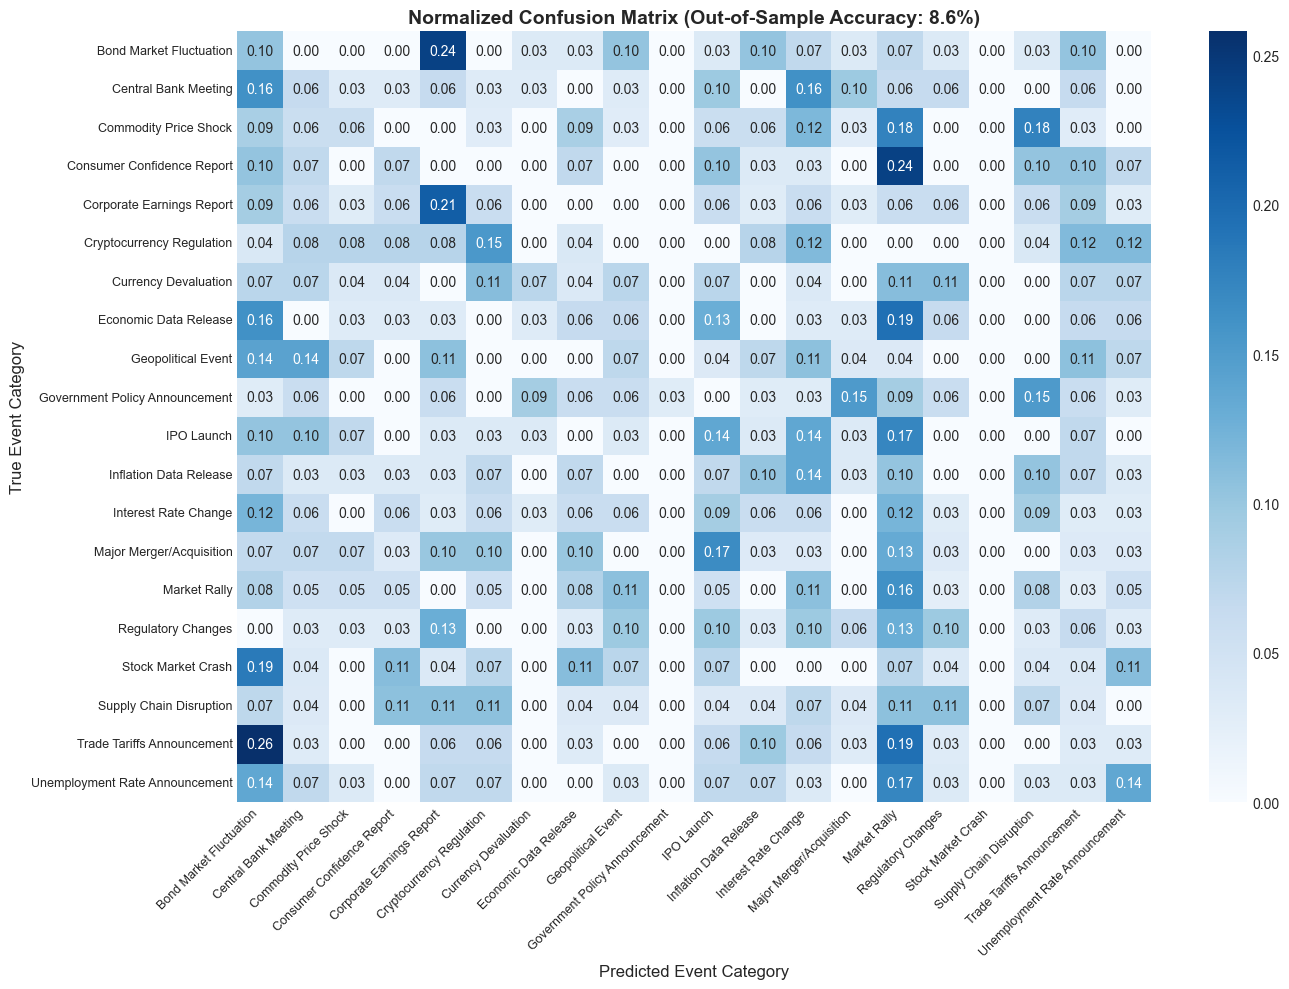

In [7]:
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(14, 10))
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap='Blues', 
    xticklabels=labels, 
    yticklabels=labels,
    cbar=True
)
plt.title(f"Normalized Confusion Matrix (Out-of-Sample Accuracy: {test_acc*100:.1f}%)", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Event Category", fontsize=12)
plt.ylabel("True Event Category", fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
sample_test_headlines = [
    "Federal Reserve decides to cut benchmark interest rate by 50 basis points",
    "Tech conglomerate announces record quarterly earnings and $20B share repurchase program",
    "New trade tariffs imposed on imported semiconductor chips amidst rising tensions",
    "Supply chain crisis deepens as major port workers extend nationwide strike",
    "Company files for Initial Public Offering aiming for $5 billion valuation"
]

print("--- Live Inference on Sample Financial Headlines ---")
for headline in sample_test_headlines:
    cleaned = clean_financial_text(headline)
    predicted_category = best_pipeline.predict([cleaned])[0]
    print(f"\nHeadline : \"{headline}\"")
    print(f"Predicted Event Category: [{predicted_category}]")

--- Live Inference on Sample Financial Headlines ---

Headline : "Federal Reserve decides to cut benchmark interest rate by 50 basis points"
Predicted Event Category: [Interest Rate Change]

Headline : "Tech conglomerate announces record quarterly earnings and $20B share repurchase program"
Predicted Event Category: [Corporate Earnings Report]

Headline : "New trade tariffs imposed on imported semiconductor chips amidst rising tensions"
Predicted Event Category: [Trade Tariffs Announcement]

Headline : "Supply chain crisis deepens as major port workers extend nationwide strike"
Predicted Event Category: [Supply Chain Disruption]

Headline : "Company files for Initial Public Offering aiming for $5 billion valuation"
Predicted Event Category: [Market Rally]


In [9]:
# Ensure models directory exists
MODEL_DIR = os.path.join("..", "models")
if not os.path.exists(MODEL_DIR):
    MODEL_DIR = os.path.join("models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_OUTPUT_PATH = os.path.join(MODEL_DIR, "event_classifier_pipeline.joblib")

# Save complete pipeline
joblib.dump(best_pipeline, MODEL_OUTPUT_PATH)

print(f"Production NLP Pipeline serialized and saved to: {MODEL_OUTPUT_PATH}")
print(f"File Size: {os.path.getsize(MODEL_OUTPUT_PATH) / 1024:.1f} KB")

# Verify loading works
loaded_pipeline = joblib.load(MODEL_OUTPUT_PATH)
verification_pred = loaded_pipeline.predict(["Central bank holds emergency meeting regarding interest rates"])[0]
print(f"Pipeline verification test prediction: '{verification_pred}'")

Production NLP Pipeline serialized and saved to: ..\models\event_classifier_pipeline.joblib
File Size: 127.5 KB
Pipeline verification test prediction: 'Central Bank Meeting'
